# A1 — ResNet18 and Swin-T on CIFAR-100

Compare CNN and Transformer models trained from scratch or with ImageNet pretraining. The pretrained models use head-only, partial, and full fine-tuning.

This notebook contains the data preparation, models, training loops, and analysis. Run it from top to bottom in an environment with `torch`, `torchvision`, `numpy`, `pandas`, and `matplotlib`. A GPU is recommended for the full experiment.

In [1]:
%pip install -q torch torchvision numpy pandas matplotlib scikit-learn pillow


Note: you may need to restart the kernel to use updated packages.


## 1. Settings

Use all 100 classes: 45,000 training, 5,000 validation, and 10,000 test images. The fixed protocol includes eight configurations × three seeds × 20 epochs, followed by two Swin-T configurations × three seeds × 40 epochs: **30 runs and 720 epochs**.

The 40-epoch comparison gives scratch and pretrained Swin-T the same learning rate, weight decay, and warmup. All runs finish training before the held-out test set is evaluated. Validation accuracy selects each checkpoint; lower validation cross-entropy breaks ties, then the earlier epoch is retained.

In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import gc
import json
import random
import time
from contextlib import nullcontext
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import CIFAR100
from torchvision.datasets.utils import download_url
from torchvision.models import (
    ResNet18_Weights, Swin_T_Weights, resnet18, swin_t,
)


def choose_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


DEVICE = choose_device()
USE_BF16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)
NUM_WORKERS = 4 if DEVICE.type == "cuda" else 0
DATA_DIR = Path("data")
RUN_DIR = Path("runs") / "A1" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir()

SEEDS = [42, 43, 44]
SPLIT_SEED = 2026
BATCH_SIZE = 128
IMAGE_SIZE = 96
N_CLASSES = 100
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

torch.set_num_threads(4)
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

print("Device:", DEVICE, "| precision:", "BF16 autocast" if USE_BF16 else "FP32")
print("Output:", RUN_DIR.resolve())


Device: cuda | precision: BF16 autocast
Output: /workspace/coursework/runs/A1/20261107T150346212192Z


In [3]:
basic_experiments = [
    {"id": "resnet18_scratch", "family": "resnet18", "regime": "scratch", "lr": 1e-3},
    {"id": "resnet18_head", "family": "resnet18", "regime": "head", "lr": 1e-3},
    {"id": "resnet18_partial", "family": "resnet18", "regime": "partial", "lr": 1e-4},
    {"id": "resnet18_full", "family": "resnet18", "regime": "full", "lr": 1e-4},
    {"id": "swin_t_scratch", "family": "swin_t", "regime": "scratch", "lr": 1e-3},
    {"id": "swin_t_head", "family": "swin_t", "regime": "head", "lr": 1e-3},
    {"id": "swin_t_partial", "family": "swin_t", "regime": "partial", "lr": 1e-4},
    {"id": "swin_t_full", "family": "swin_t", "regime": "full", "lr": 1e-4},
]
followup_experiments = [
    {"id": "swin_t_scratch", "family": "swin_t", "regime": "scratch", "lr": 2e-4},
    {"id": "swin_t_full", "family": "swin_t", "regime": "full", "lr": 2e-4},
]
studies = [
    {"study": "basic_20", "epochs": 20, "weight_decay": 1e-4,
     "warmup_epochs": 0, "experiments": basic_experiments},
    {"study": "swin_matched_40", "epochs": 40, "weight_decay": 0.01,
     "warmup_epochs": 5, "experiments": followup_experiments},
]
assert sum(len(s["experiments"]) * len(SEEDS) * s["epochs"] for s in studies) == 720

settings = {
    "studies": studies, "seeds": SEEDS, "split_seed": SPLIT_SEED,
    "dataset": "CIFAR100", "train_size": 45000, "val_size": 5000, "test_size": 10000,
    "classes": N_CLASSES, "batch_size": BATCH_SIZE, "image_size": IMAGE_SIZE,
    "mean": MEAN, "std": STD, "num_workers": NUM_WORKERS,
    "train_transform": "RandomCrop(32,padding=4), RandomHorizontalFlip(0.5), Resize(96,bilinear,antialias=True), ToTensor, Normalize",
    "eval_transform": "Resize(96,bilinear,antialias=True), ToTensor, Normalize",
    "augmentation_rng": "Seeded Python/NumPy/PyTorch; seeded DataLoader generator and workers; nonpersistent workers",
    "optimizer": "AdamW", "betas": [0.9, 0.999], "eps": 1e-8,
    "scheduler": "Per-epoch cosine to zero; follow-up: 5-epoch linear warmup from 0.1x then 35-epoch cosine",
    "loss": "CrossEntropyLoss without label smoothing", "gradient_clip": 1.0,
    "selection": "Highest validation accuracy, then lowest CE, then earliest epoch",
    "device": str(DEVICE), "precision": "BF16 autocast" if USE_BF16 else "FP32",
    "torch": torch.__version__, "torchvision": torchvision.__version__,
    "tf32": False, "compile": False,
    "train_seconds": "Synchronized training passes, including data loading; excludes validation and checkpoint writes",
    "seconds_per_epoch": "Mean synchronized training + validation duration; excludes checkpoint writes",
    "peak_memory_mib": "CUDA peak allocated tensor memory over training/validation; unavailable on MPS/CPU",
}
if DEVICE.type == "cuda":
    settings["device_name"] = torch.cuda.get_device_name(DEVICE)
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2))
display(pd.DataFrame([
    {"study": study["study"], "epochs": study["epochs"],
     "weight_decay": study["weight_decay"], "warmup_epochs": study["warmup_epochs"], **exp}
    for study in studies for exp in study["experiments"]
]))


,study,epochs,weight_decay,warmup_epochs,id,family,regime,lr
0,basic_20,20,0.0001,0,resnet18_scratch,resnet18,scratch,0.0010
1,basic_20,20,0.0001,0,resnet18_head,resnet18,head,0.0010
2,basic_20,20,0.0001,0,resnet18_partial,resnet18,partial,0.0001
3,basic_20,20,0.0001,0,resnet18_full,resnet18,full,0.0001
4,basic_20,20,0.0001,0,swin_t_scratch,swin_t,scratch,0.0010
5,basic_20,20,0.0001,0,swin_t_head,swin_t,head,0.0010
6,basic_20,20,0.0001,0,swin_t_partial,swin_t,partial,0.0001
7,basic_20,20,0.0001,0,swin_t_full,swin_t,full,0.0001
8,swin_matched_40,40,0.0100,5,swin_t_scratch,swin_t,scratch,0.0002
9,swin_matched_40,40,0.0100,5,swin_t_full,swin_t,full,0.0002


## 2. Data and exploration

[CIFAR-100](https://www.cs.toronto.edu/~kriz/cifar.html) contains 60,000 RGB images at 32 × 32 pixels, with 100 fine classes grouped into 20 coarse classes. The Python archive stores image arrays and labels in `train` and `test`, with class names in `meta`. This experiment predicts the 100 fine classes.

The official training set is split into 450 training and 50 validation images per class. Training uses random crop with padding and horizontal flip before resizing to 96 × 96. Validation and test use resizing and ImageNet normalization. Upsampling changes the input size without adding image detail.

In [4]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / CIFAR100.base_folder / "meta").is_file():
    download_url(
        "https://zenodo.org/records/10089977/files/cifar-100-python.tar.gz?download=1",
        str(DATA_DIR), filename=CIFAR100.filename, md5=CIFAR100.tgz_md5,
    )

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR,
                      antialias=True),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR,
                      antialias=True),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
train_base = CIFAR100(str(DATA_DIR), train=True, download=True, transform=train_transform)
val_base = CIFAR100(str(DATA_DIR), train=True, download=False, transform=eval_transform)
labels = np.asarray(train_base.targets)
classes = train_base.classes
assert len(labels) == 50000 and len(classes) == N_CLASSES
assert np.array_equal(np.bincount(labels, minlength=N_CLASSES), np.full(N_CLASSES, 500))

rng = np.random.default_rng(SPLIT_SEED)
train_indices, val_indices = [], []
for class_id in range(N_CLASSES):
    indices = np.flatnonzero(labels == class_id)
    rng.shuffle(indices)
    val_indices.extend(indices[:50].tolist())
    train_indices.extend(indices[50:].tolist())
train_indices.sort()
val_indices.sort()
train_data = Subset(train_base, train_indices)
val_data = Subset(val_base, val_indices)
assert len(train_data) == 45000 and len(val_data) == 5000
assert set(train_indices).isdisjoint(val_indices)
(RUN_DIR / "split.json").write_text(json.dumps({
    "split_seed": SPLIT_SEED, "train_indices": train_indices,
    "val_indices": val_indices, "classes": classes,
}))

class_counts = pd.DataFrame({
    "class": classes,
    "train": np.bincount(labels[train_indices], minlength=N_CLASSES),
    "validation": np.bincount(labels[val_indices], minlength=N_CLASSES),
})
class_counts.to_csv(RUN_DIR / "class_counts.csv", index=False)
display(class_counts)
print("Original image shape:", train_base.data.shape[1:])


  0%|          | 0.00/169M [00:00<?, ?B/s]

  0%|          | 32.8k/169M [00:00<38:49, 72.5kB/s]

  0%|          | 98.3k/169M [00:00<16:31, 170kB/s] 

  0%|          | 164k/169M [00:00<13:02, 216kB/s] 

  0%|          | 328k/169M [00:01<07:24, 379kB/s]

  0%|          | 393k/169M [00:01<08:02, 350kB/s]

... (802 outputs left out)

100%|██████████| 169M/169M [03:02<00:00, 927kB/s] 

/usr/local/lib/python3.12/dist-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


,class,train,validation
0,apple,450,50
1,aquarium_fish,450,50
2,baby,450,50
3,bear,450,50
4,beaver,450,50
...,...,...,...
95,whale,450,50
96,willow_tree,450,50
97,wolf,450,50
98,woman,450,50


Original image shape: (32, 32, 3)


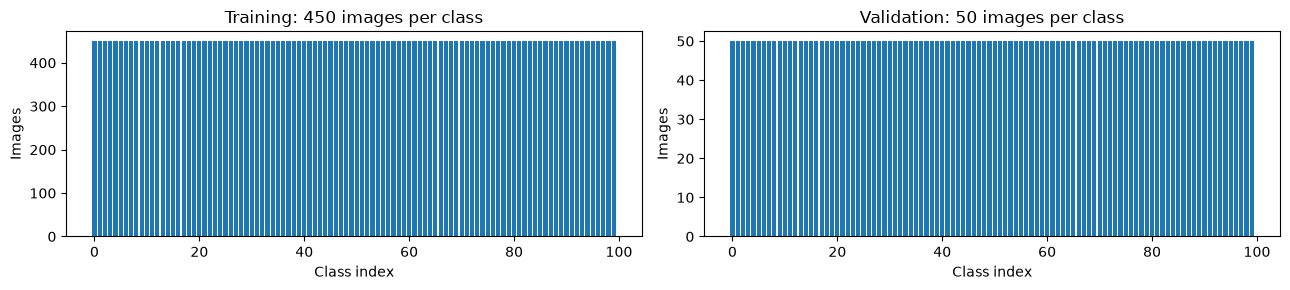

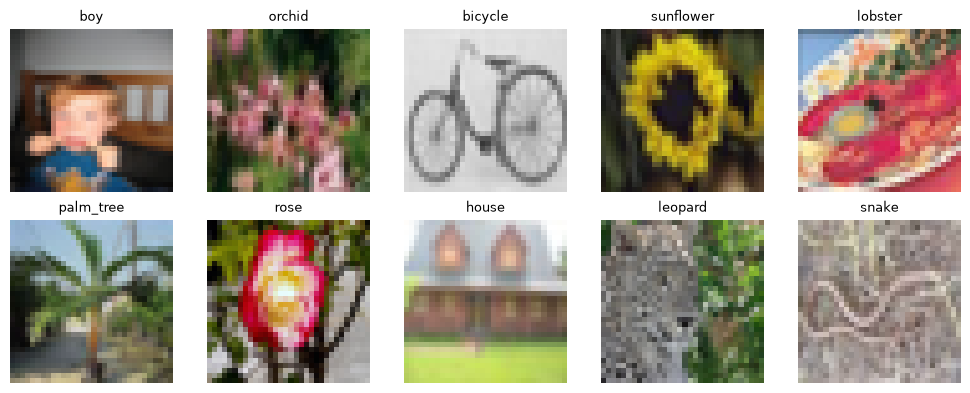

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
axes[0].bar(np.arange(N_CLASSES), class_counts["train"])
axes[1].bar(np.arange(N_CLASSES), class_counts["validation"])
for ax, title in zip(axes, ["Training: 450 images per class", "Validation: 50 images per class"]):
    ax.set(title=title, xlabel="Class index", ylabel="Images")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_counts.png", dpi=150)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
example_indices = np.random.default_rng(SEEDS[0]).choice(train_indices, 10, replace=False)
for ax, index in zip(axes.flat, example_indices):
    ax.imshow(train_base.data[index])
    ax.set_title(classes[labels[index]], fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_samples.png", dpi=150)
plt.show()
plt.close(fig)


### Normalization and augmentation examples

ImageNet normalization uses the channelwise operation $(x-\mu)/\sigma$ after scaling pixels to $[0,1]$. The table below compares the same ten illustrative training images before and after augmentation, resizing, and normalization; these are sample statistics, not dataset-wide estimates. The second row reverses normalization for display.

ImageNet mean: [0.485, 0.456, 0.406] | standard deviation: [0.229, 0.224, 0.225]


,channel,original_mean,original_std,normalized_mean,normalized_std,normalization_mean,normalization_std
0,R,0.5315,0.2405,-0.1171,1.1994,0.485,0.229
1,G,0.4806,0.2273,-0.1980,1.1278,0.456,0.224
2,B,0.4090,0.2461,-0.2658,1.1214,0.406,0.225


Original sample pixel range: 0.0 1.0
Normalized sample pixel range: -2.1179039478302 2.640000104904175


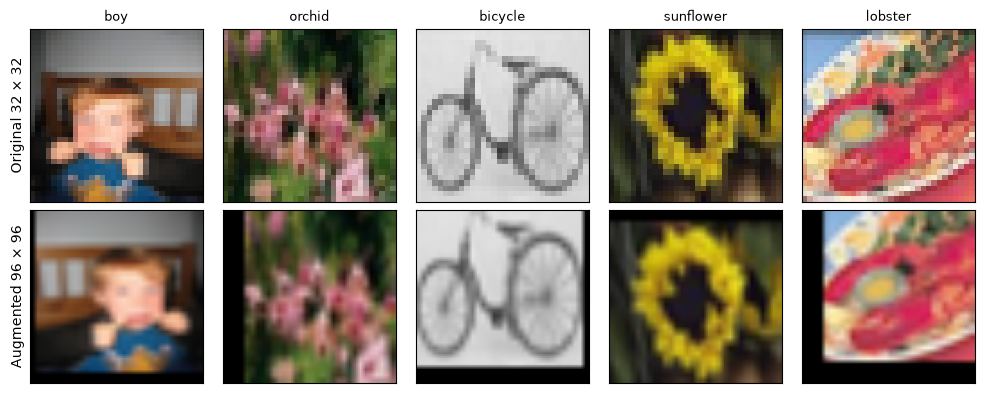

In [6]:
print("ImageNet mean:", MEAN, "| standard deviation:", STD)
torch.manual_seed(SEEDS[0])
augmented = torch.stack([train_base[int(index)][0] for index in example_indices])
original = torch.from_numpy(train_base.data[example_indices]).permute(0, 3, 1, 2).float() / 255
pixel_statistics = pd.DataFrame({
    "channel": ["R", "G", "B"],
    "original_mean": original.mean((0, 2, 3)).numpy(),
    "original_std": original.std((0, 2, 3), unbiased=False).numpy(),
    "normalized_mean": augmented.mean((0, 2, 3)).numpy(),
    "normalized_std": augmented.std((0, 2, 3), unbiased=False).numpy(),
    "normalization_mean": MEAN, "normalization_std": STD,
})
pixel_statistics.to_csv(RUN_DIR / "sample_pixel_statistics.csv", index=False)
display(pixel_statistics.round(4))
print("Original sample pixel range:", float(original.min()), float(original.max()))
print("Normalized sample pixel range:", float(augmented.min()), float(augmented.max()))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
mean_tensor = torch.tensor(MEAN).view(3, 1, 1)
std_tensor = torch.tensor(STD).view(3, 1, 1)
for column in range(5):
    axes[0, column].imshow(original[column].permute(1, 2, 0))
    visible = (augmented[column] * std_tensor + mean_tensor).clamp(0, 1)
    axes[1, column].imshow(visible.permute(1, 2, 0))
    axes[0, column].set_title(classes[labels[example_indices[column]]], fontsize=9)
    for row in range(2):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
axes[0, 0].set_ylabel("Original 32 × 32")
axes[1, 0].set_ylabel("Augmented 96 × 96")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "augmentation_examples.png", dpi=150)
plt.show()
plt.close(fig)


## 3. Models

Use the standard torchvision ResNet18 and Swin-T, replacing only the final classifier with a 100-class linear layer. Pretrained runs load the official `IMAGENET1K_V1` weights.

- **Scratch / full:** train every parameter; scratch uses random initialization.
- **Head:** train only `fc` (ResNet18) or `head` (Swin-T).
- **Partial:** train `layer4` + `fc` (ResNet18), or the final stage `features.7` + `norm` + `head` (Swin-T).

Frozen submodules stay in evaluation mode, so their batch-normalization statistics and stochastic-depth behaviour remain fixed.

In [7]:
def trainable_roots(family, regime):
    if family not in ("resnet18", "swin_t") or regime not in ("scratch", "head", "partial", "full"):
        raise ValueError("Unknown family or regime")
    if regime in ("scratch", "full"):
        return [""]
    if family == "resnet18":
        return ["fc"] if regime == "head" else ["layer4", "fc"]
    return ["head"] if regime == "head" else ["features.7", "norm", "head"]


def construct_model(family, regime, pretrained=True):
    use_pretrained = pretrained and regime != "scratch"
    if family == "resnet18":
        weights = ResNet18_Weights.IMAGENET1K_V1 if use_pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, N_CLASSES)
    elif family == "swin_t":
        weights = Swin_T_Weights.IMAGENET1K_V1 if use_pretrained else None
        model = swin_t(weights=weights)
        model.head = nn.Linear(model.head.in_features, N_CLASSES)
    else:
        raise ValueError("Unknown family")
    roots = trainable_roots(family, regime)
    for name, parameter in model.named_parameters():
        parameter.requires_grad_(any(root == "" or name.startswith(root + ".") for root in roots))
    return model


def set_training_mode(model, family, regime):
    model.eval()
    for root in trainable_roots(family, regime):
        (model if root == "" else model.get_submodule(root)).train()


# Display the actual layers; this does not download weights or train a model.
for family in ("resnet18", "swin_t"):
    architecture = construct_model(family, "scratch", pretrained=False)
    print(architecture)
    del architecture


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

SwinTransformer(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=96, out_features=288, bias=True)
          (proj): Linear(in_features=96, out_features=96, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (0): Linear(in_features=96, out_features=384, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=384, out_features=96, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): SwinTransformerBlock(
       

## 4. Training and evaluation functions

For a batch with logits $z_i$ and labels $y_i$, minimize cross-entropy $-\frac{1}{B}\sum_i\log\operatorname{softmax}(z_i)_{y_i}$. AdamW updates the trainable parameters, with gradient norm clipped at 1.0. The basic study uses cosine decay over 20 epochs. The matched Swin-T study warms up from 0.1 times the peak learning rate over five epochs, then uses cosine decay over 35 epochs.

Use BF16 autocast on a compatible CUDA GPU, otherwise FP32 on the selected device. Timing synchronizes CUDA/MPS; peak allocated memory is measured only on CUDA. Seeds control initialization, shuffling, and ordinary torchvision augmentation; bitwise equality across different devices is not assumed.

In [8]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def make_loader(dataset, seed, shuffle=False):
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
        generator=torch.Generator().manual_seed(seed), worker_init_fn=seed_worker,
        persistent_workers=False, drop_last=False,
    )


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


def precision_context():
    return torch.autocast("cuda", dtype=torch.bfloat16) if USE_BF16 else nullcontext()


def train_epoch(model, batches, optimizer, family, regime):
    set_training_mode(model, family, regime)
    loss_sum, correct, count = 0.0, 0, 0
    for images, targets in batches:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with precision_context():
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Nonfinite training loss")
        loss.backward()
        nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],
                                 max_norm=1.0, error_if_nonfinite=True)
        optimizer.step()
        loss_sum += loss.item() * len(targets)
        correct += (logits.argmax(1) == targets).sum().item()
        count += len(targets)
    return {"ce": loss_sum / count, "accuracy": correct / count}


@torch.no_grad()
def evaluate(model, batches, predictions=False):
    model.eval()
    loss_sum, count = 0.0, 0
    confusion = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.int64)
    all_targets, all_predictions, all_confidences = [], [], []
    for images, targets in batches:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with precision_context():
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Nonfinite evaluation loss")
        guesses = logits.argmax(1)
        encoded = (targets * N_CLASSES + guesses).cpu()
        confusion += torch.bincount(encoded, minlength=N_CLASSES**2).reshape(N_CLASSES, N_CLASSES)
        loss_sum += loss.item() * len(targets)
        count += len(targets)
        if predictions:
            all_targets.extend(targets.cpu().tolist())
            all_predictions.extend(guesses.cpu().tolist())
            all_confidences.extend(logits.float().softmax(1).max(1).values.cpu().tolist())
    true_positive = confusion.diag().double()
    f1 = 2 * true_positive / (confusion.sum(0) + confusion.sum(1)).clamp_min(1)
    result = {"ce": loss_sum / count, "accuracy": true_positive.sum().item() / count,
              "macro_f1": f1.mean().item(), "confusion": confusion.numpy()}
    if predictions:
        result["predictions"] = pd.DataFrame({
            "index": np.arange(count), "target": all_targets,
            "prediction": all_predictions, "confidence": all_confidences,
        })
    return result


In [9]:
def fit(study, experiment, seed):
    seed_everything(seed)
    family, regime = experiment["family"], experiment["regime"]
    run = RUN_DIR / study["study"] / experiment["id"] / f"seed_{seed}"
    run.mkdir(parents=True, exist_ok=False)
    model = construct_model(family, regime).to(DEVICE)
    n_parameters = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=experiment["lr"],
        weight_decay=study["weight_decay"], betas=(0.9, 0.999), eps=1e-8,
    )
    warmup = study["warmup_epochs"]
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=study["epochs"] - warmup, eta_min=0,
    )
    if warmup:
        linear = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=warmup)
        scheduler = torch.optim.lr_scheduler.SequentialLR(
            optimizer, schedulers=[linear, cosine], milestones=[warmup],
        )
    else:
        scheduler = cosine
    train_batches = make_loader(train_data, seed, shuffle=True)
    val_batches = make_loader(val_data, seed + 1)
    history, best_score, best_epoch = [], (-1.0, -float("inf")), 0
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)
    for epoch in range(1, study["epochs"] + 1):
        lr = optimizer.param_groups[0]["lr"]
        synchronize()
        start = time.perf_counter()
        training = train_epoch(model, train_batches, optimizer, family, regime)
        synchronize()
        train_seconds = time.perf_counter() - start
        validation = evaluate(model, val_batches)
        synchronize()
        epoch_seconds = time.perf_counter() - start
        history.append({
            "epoch": epoch, "lr": lr, "train_ce": training["ce"],
            "train_accuracy": training["accuracy"], "val_ce": validation["ce"],
            "val_accuracy": validation["accuracy"], "val_macro_f1": validation["macro_f1"],
            "train_seconds": train_seconds, "epoch_seconds": epoch_seconds,
        })
        score = (validation["accuracy"], -validation["ce"])
        if score > best_score:
            best_score, best_epoch = score, epoch
            torch.save({"model": model.state_dict(), "best_epoch": best_epoch}, run / "best.pt")
        scheduler.step()
        pd.DataFrame(history).to_csv(run / "history.csv", index=False)
        print(f'{study["study"]} | {experiment["id"]} | seed {seed} | '
              f'{epoch:02d}/{study["epochs"]} | val accuracy {validation["accuracy"]:.4f}', flush=True)
    peak_memory = torch.cuda.max_memory_allocated(DEVICE) / 2**20 if DEVICE.type == "cuda" else None
    record = {
        "study": study["study"], "id": experiment["id"], "family": family,
        "regime": regime, "seed": seed, "val_accuracy": best_score[0],
        "n_parameters": n_parameters, "n_trainable": n_trainable,
        "train_seconds": sum(row["train_seconds"] for row in history),
        "seconds_per_epoch": sum(row["epoch_seconds"] for row in history) / len(history),
        "peak_memory_mib": peak_memory, "best_epoch": best_epoch,
    }
    (run / "training.json").write_text(json.dumps(record, indent=2))
    del model, optimizer, scheduler, cosine, train_batches, val_batches
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return {"record": record, "run": run, "history": history}


## 5. Train all configurations

The test set is not used in this cell. Each run writes its best checkpoint and per-epoch history to a fresh output directory.

In [10]:
jobs = []
for study in studies:
    for experiment in study["experiments"]:
        for seed in SEEDS:
            jobs.append(fit(study, experiment, seed))
assert len(jobs) == 30
assert sum(len(job["history"]) for job in jobs) == 720

histories = pd.concat([
    pd.DataFrame(job["history"]).assign(
        study=job["record"]["study"], id=job["record"]["id"], seed=job["record"]["seed"],
    ) for job in jobs
], ignore_index=True)
histories.to_csv(RUN_DIR / "histories.csv", index=False)


basic_20 | resnet18_scratch | seed 42 | 01/20 | val accuracy 0.1598


basic_20 | resnet18_scratch | seed 42 | 02/20 | val accuracy 0.2770


basic_20 | resnet18_scratch | seed 42 | 03/20 | val accuracy 0.3672


basic_20 | resnet18_scratch | seed 42 | 04/20 | val accuracy 0.3752


basic_20 | resnet18_scratch | seed 42 | 05/20 | val accuracy 0.4354


basic_20 | resnet18_scratch | seed 42 | 06/20 | val accuracy 0.4862


... (736 outputs left out)

swin_matched_40 | swin_t_full | seed 44 | 37/40 | val accuracy 0.8612


swin_matched_40 | swin_t_full | seed 44 | 38/40 | val accuracy 0.8626


swin_matched_40 | swin_t_full | seed 44 | 39/40 | val accuracy 0.8604


swin_matched_40 | swin_t_full | seed 44 | 40/40 | val accuracy 0.8604


## 6. Held-out test evaluation

The protocol is fixed above. After all 720 training epochs finish, evaluate each selected checkpoint on all 10,000 official test images. Accuracy is the fraction of correct predictions; macro-F1 averages the 100 classwise F1 scores equally. Save predictions and confusion matrices for error analysis.

/usr/local/lib/python3.12/dist-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


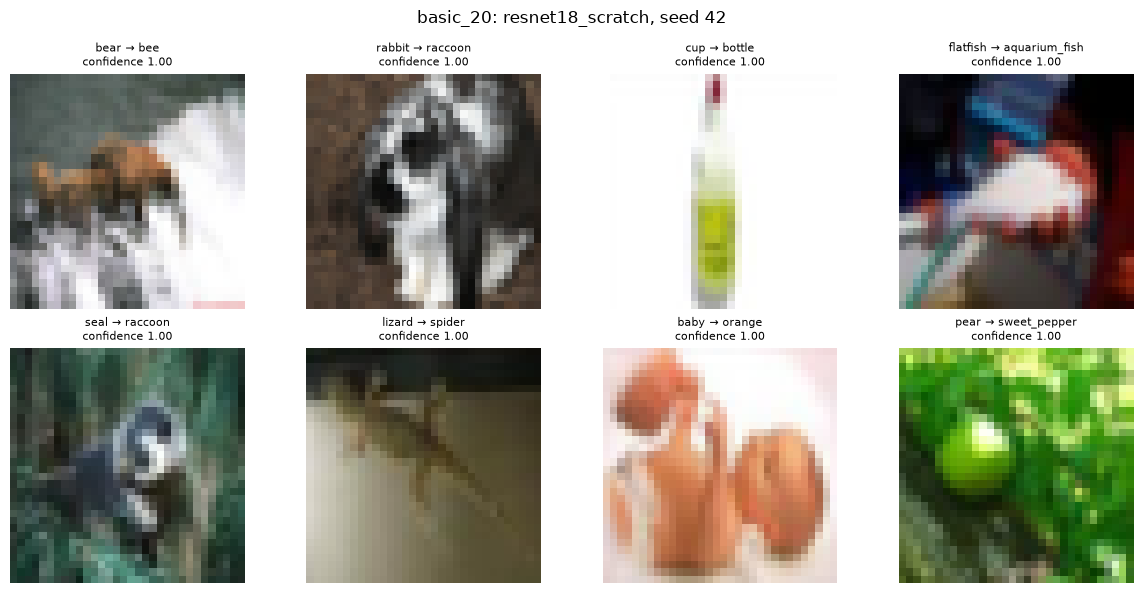

basic_20 | resnet18_scratch | seed 42 | test accuracy 0.6416


basic_20 | resnet18_scratch | seed 43 | test accuracy 0.6487


basic_20 | resnet18_scratch | seed 44 | test accuracy 0.6455


basic_20 | resnet18_head | seed 42 | test accuracy 0.6096


basic_20 | resnet18_head | seed 43 | test accuracy 0.6085


basic_20 | resnet18_head | seed 44 | test accuracy 0.6085


basic_20 | resnet18_partial | seed 42 | test accuracy 0.7386


basic_20 | resnet18_partial | seed 43 | test accuracy 0.7411


basic_20 | resnet18_partial | seed 44 | test accuracy 0.7377


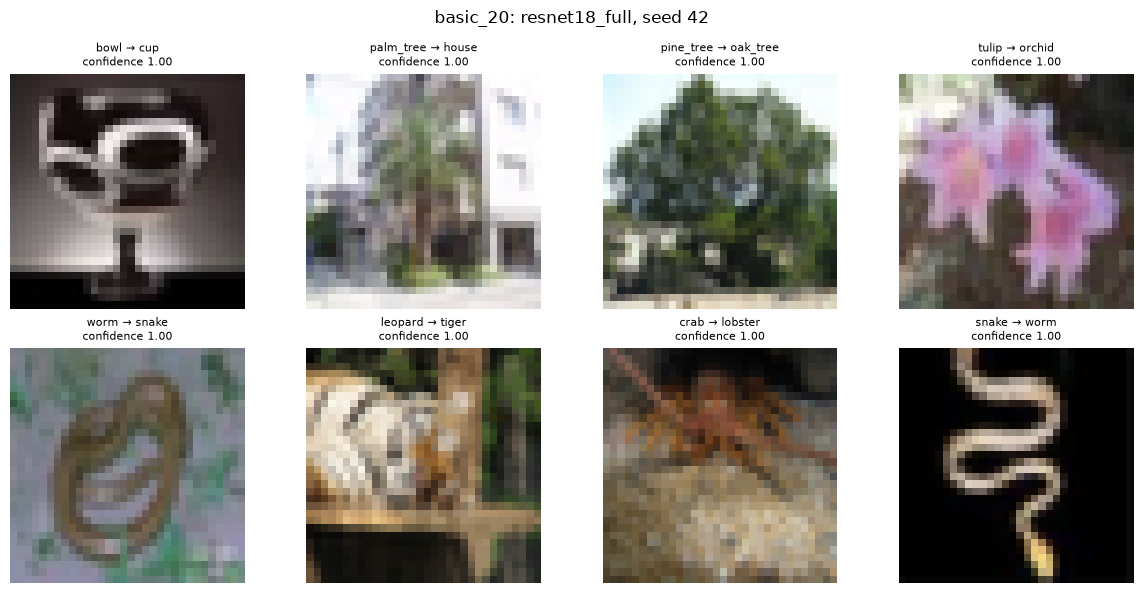

basic_20 | resnet18_full | seed 42 | test accuracy 0.7884


basic_20 | resnet18_full | seed 43 | test accuracy 0.7890


basic_20 | resnet18_full | seed 44 | test accuracy 0.7904


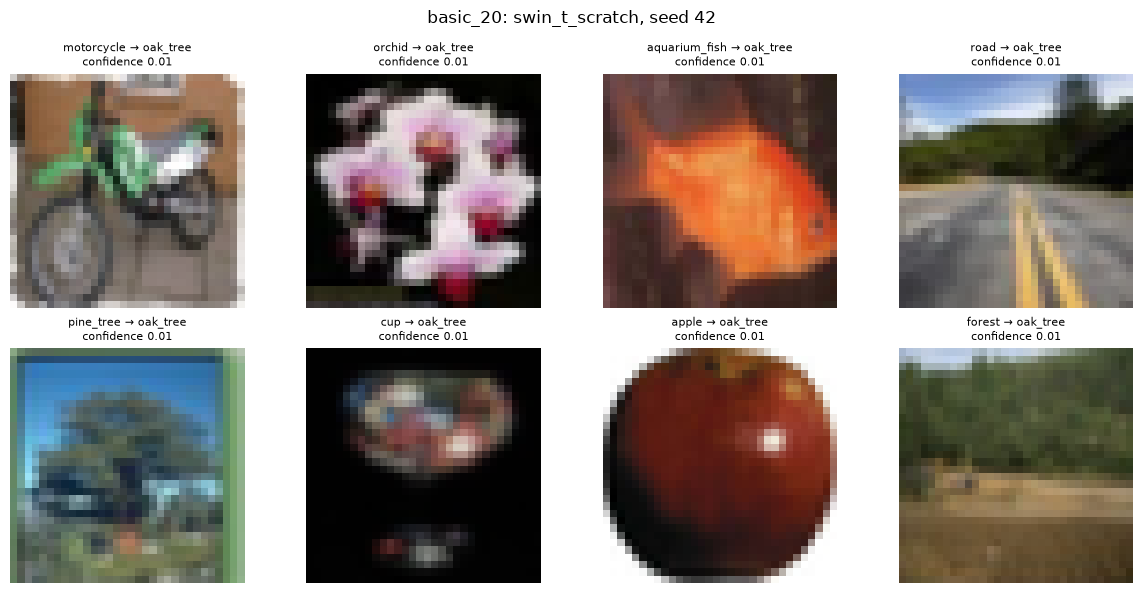

basic_20 | swin_t_scratch | seed 42 | test accuracy 0.0100


basic_20 | swin_t_scratch | seed 43 | test accuracy 0.0366


basic_20 | swin_t_scratch | seed 44 | test accuracy 0.0191


basic_20 | swin_t_head | seed 42 | test accuracy 0.7170


basic_20 | swin_t_head | seed 43 | test accuracy 0.7174


basic_20 | swin_t_head | seed 44 | test accuracy 0.7180


basic_20 | swin_t_partial | seed 42 | test accuracy 0.7820


basic_20 | swin_t_partial | seed 43 | test accuracy 0.7864


basic_20 | swin_t_partial | seed 44 | test accuracy 0.7818


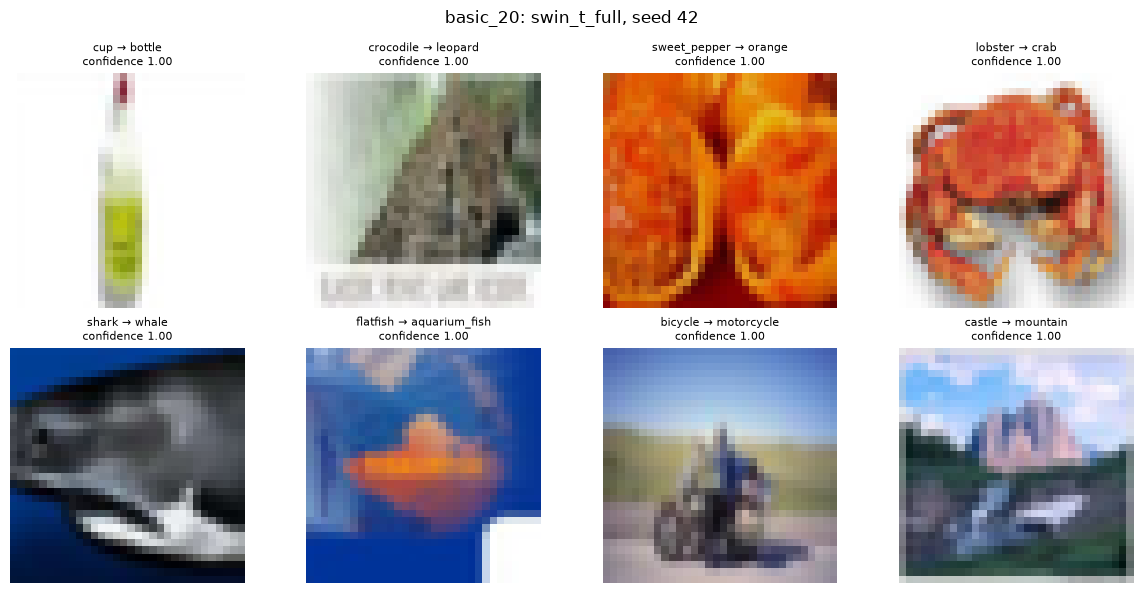

basic_20 | swin_t_full | seed 42 | test accuracy 0.8650


basic_20 | swin_t_full | seed 43 | test accuracy 0.8632


basic_20 | swin_t_full | seed 44 | test accuracy 0.8679


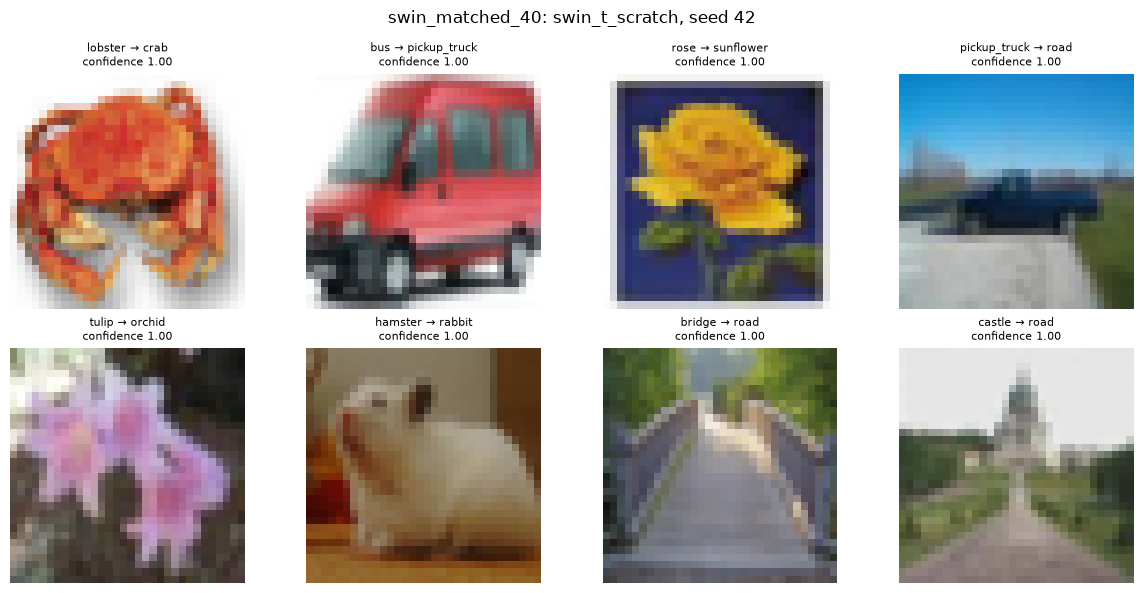

swin_matched_40 | swin_t_scratch | seed 42 | test accuracy 0.6050


swin_matched_40 | swin_t_scratch | seed 43 | test accuracy 0.5956


swin_matched_40 | swin_t_scratch | seed 44 | test accuracy 0.5994


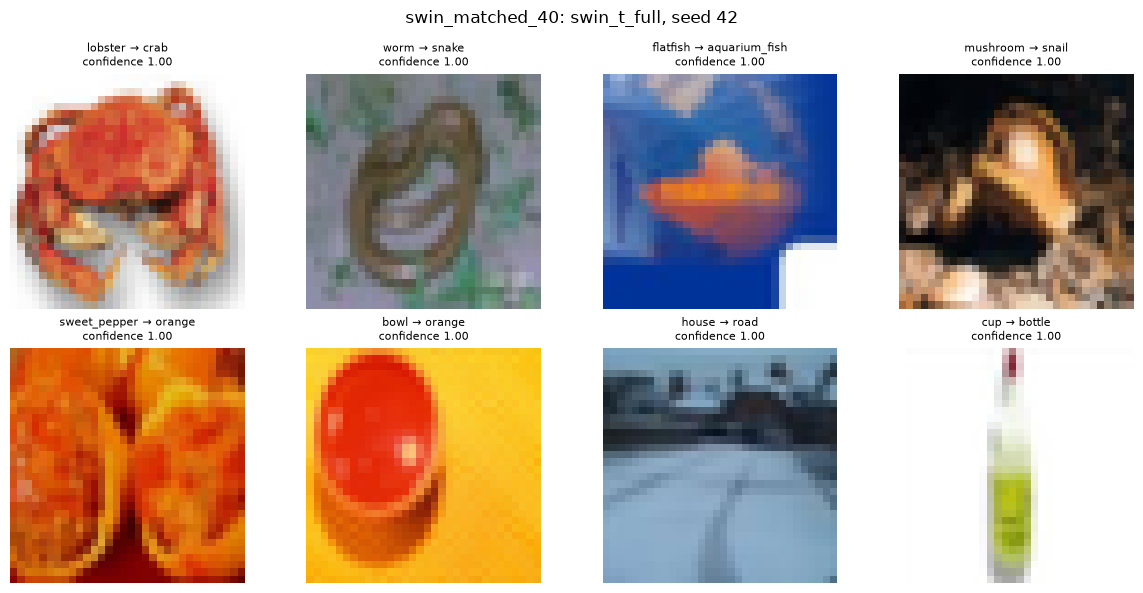

swin_matched_40 | swin_t_full | seed 42 | test accuracy 0.8649


swin_matched_40 | swin_t_full | seed 43 | test accuracy 0.8624


swin_matched_40 | swin_t_full | seed 44 | test accuracy 0.8661


,study,id,family,regime,seed,val_accuracy,test_accuracy,test_macro_f1,n_parameters,n_trainable,train_seconds,seconds_per_epoch,peak_memory_mib,best_epoch
0,basic_20,resnet18_scratch,resnet18,scratch,42,0.6408,0.6416,0.6407,11227812,11227812,72.5790,4.0691,522.3604,20
1,basic_20,resnet18_scratch,resnet18,scratch,43,0.6444,0.6487,0.6469,11227812,11227812,78.7305,4.4544,522.6104,18
2,basic_20,resnet18_scratch,resnet18,scratch,44,0.6424,0.6455,0.6448,11227812,11227812,77.9243,4.4124,522.6104,20
3,basic_20,resnet18_head,resnet18,head,42,0.6200,0.6096,0.6084,11227812,51300,63.9772,3.6519,252.1396,19
4,basic_20,resnet18_head,resnet18,head,43,0.6198,0.6085,0.6068,11227812,51300,63.9070,3.6462,252.1396,18
5,basic_20,resnet18_head,resnet18,head,44,0.6220,0.6085,0.6075,11227812,51300,64.1382,3.6579,252.1396,19
6,basic_20,resnet18_partial,resnet18,partial,42,0.7406,0.7386,0.7381,11227812,8445028,64.1704,3.6608,347.3232,17
7,basic_20,resnet18_partial,resnet18,partial,43,0.7418,0.7411,0.7407,11227812,8445028,64.2822,3.6660,347.3232,19
8,basic_20,resnet18_partial,resnet18,partial,44,0.7388,0.7377,0.7376,11227812,8445028,64.8006,3.6961,347.3232,18
9,basic_20,resnet18_full,resnet18,full,42,0.7866,0.7884,0.7883,11227812,11227812,66.8356,3.7975,522.6104,18


In [11]:
test_data = CIFAR100(str(DATA_DIR), train=False, download=False, transform=eval_transform)
assert len(test_data) == 10000
assert np.array_equal(np.bincount(test_data.targets, minlength=N_CLASSES), np.full(N_CLASSES, 100))
rows, matrices, prediction_tables = [], {}, []
for job in jobs:
    record, run = job["record"].copy(), job["run"]
    model = construct_model(record["family"], record["regime"], pretrained=False).to(DEVICE)
    checkpoint = torch.load(run / "best.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model"])
    test_batches = make_loader(test_data, record["seed"] + 2)
    metrics = evaluate(model, test_batches, predictions=True)
    record.update(test_accuracy=metrics["accuracy"], test_macro_f1=metrics["macro_f1"])
    rows.append(record)
    prediction_table = metrics["predictions"]
    prediction_table.to_csv(run / "predictions.csv", index=False)
    prediction_tables.append(prediction_table.assign(
        study=record["study"], id=record["id"], seed=record["seed"],
    ))
    matrix = metrics["confusion"]
    (run / "confusion.json").write_text(json.dumps({"classes": classes, "matrix": matrix.tolist()}))
    (run / "metrics.json").write_text(json.dumps({
        **record, "test_ce": metrics["ce"],
    }, indent=2))
    key = (record["study"], record["id"])
    matrices[key] = matrices.get(key, np.zeros((N_CLASSES, N_CLASSES), dtype=np.int64)) + matrix
    per_class = pd.DataFrame({
        "class": classes, "support": matrix.sum(1), "correct": matrix.diagonal(),
        "errors": matrix.sum(1) - matrix.diagonal(),
        "recall": matrix.diagonal() / matrix.sum(1),
    })
    per_class.to_csv(run / "class_errors.csv", index=False)

    # Use the first seed for image examples, without selecting a seed by test score.
    if record["seed"] == SEEDS[0] and record["regime"] in ("scratch", "full"):
        errors = prediction_table.query("target != prediction").nlargest(8, "confidence")
        if not errors.empty:
            fig, axes = plt.subplots(2, 4, figsize=(12, 6))
            for ax in axes.flat:
                ax.axis("off")
            for ax, error in zip(axes.flat, errors.itertuples()):
                ax.imshow(test_data.data[error.index])
                ax.set_title(f"{classes[error.target]} → {classes[error.prediction]}\n"
                             f"confidence {error.confidence:.2f}", fontsize=8)
            fig.suptitle(f'{record["study"]}: {record["id"]}, seed {record["seed"]}')
            fig.tight_layout()
            fig.savefig(FIGURE_DIR / f'{record["study"]}_{record["id"]}_errors.png', dpi=150)
            plt.show()
            plt.close(fig)
    print(f'{record["study"]} | {record["id"]} | seed {record["seed"]} | '
          f'test accuracy {record["test_accuracy"]:.4f}', flush=True)
    del model, checkpoint, test_batches
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

columns = ["study", "id", "family", "regime", "seed", "val_accuracy", "test_accuracy",
           "test_macro_f1", "n_parameters", "n_trainable", "train_seconds",
           "seconds_per_epoch", "peak_memory_mib", "best_epoch"]
results = pd.DataFrame(rows)[columns]
results.to_csv(RUN_DIR / "results.csv", index=False)
pd.concat(prediction_tables, ignore_index=True).to_csv(RUN_DIR / "predictions.csv", index=False)
display(results.round(4))


## 7. Comparison tables

Report mean and sample standard deviation across the three seeds. Keep the 20-epoch and 40-epoch studies separate: learning rate, weight decay, and schedule also differ across these budgets. The 40-epoch scratch/full pair is matched on all these settings. Cost comparisons apply to this device and precision; memory values are unavailable on MPS/CPU.

In [12]:
score_columns = ["val_accuracy", "test_accuracy", "test_macro_f1"]
for study in studies:
    study_results = results[results["study"] == study["study"]]
    scores = study_results.groupby("id", sort=False)[score_columns].agg(["mean", "std"])
    costs = study_results.groupby("id", sort=False)[
        ["n_parameters", "n_trainable", "train_seconds", "seconds_per_epoch", "peak_memory_mib"]
    ].mean()
    print(study["study"])
    display(scores.round(4))
    display(costs.round(2))
    scores.to_csv(RUN_DIR / f'{study["study"]}_scores.csv')
    costs.to_csv(RUN_DIR / f'{study["study"]}_costs.csv')

# Paired differences use the same seed on both sides.
matched = results[results["study"] == "swin_matched_40"].pivot(
    index="seed", columns="regime", values="test_accuracy",
)
matched["full_minus_scratch_pp"] = 100 * (matched["full"] - matched["scratch"])
matched.to_csv(RUN_DIR / "swin_matched_40_paired.csv")
display(matched.round(4))
print("Matched full − scratch (percentage points):",
      round(matched["full_minus_scratch_pp"].mean(), 3), "±",
      round(matched["full_minus_scratch_pp"].std(ddof=1), 3))


basic_20


val_accuracy         test_accuracy         test_macro_f1  \
                         mean     std          mean     std          mean   
id                                                                          
resnet18_scratch       0.6425  0.0018        0.6453  0.0036        0.6441   
resnet18_head          0.6206  0.0012        0.6089  0.0006        0.6076   
resnet18_partial       0.7404  0.0015        0.7391  0.0018        0.7388   
resnet18_full          0.7887  0.0019        0.7893  0.0010        0.7891   
swin_t_scratch         0.0226  0.0149        0.0219  0.0135        0.0067   
swin_t_head            0.7237  0.0011        0.7175  0.0005        0.7161   
swin_t_partial         0.7869  0.0006        0.7834  0.0026        0.7826   
swin_t_full            0.8698  0.0011        0.8654  0.0024        0.8653   

                          
                     std  
id                        
resnet18_scratch  0.0032  
resnet18_head     0.0008  
resnet18_partial  0.0017  
resnet18_full     0.0011  
swin_t_scratch    0.0075  
swin_t_head       0.0007  
swin_t_partial    0.0026  
swin_t_full       0.0025

,n_parameters,n_trainable,train_seconds,seconds_per_epoch,peak_memory_mib
id,,,,,
resnet18_scratch,11227812.0,11227812.0,76.41,4.31,522.53
resnet18_head,11227812.0,51300.0,64.01,3.65,252.14
resnet18_partial,11227812.0,8445028.0,64.42,3.67,347.32
resnet18_full,11227812.0,11227812.0,66.81,3.80,522.61
swin_t_scratch,27596254.0,27596254.0,213.00,11.28,2456.94
swin_t_head,27596254.0,76900.0,84.96,4.87,502.18
swin_t_partial,27596254.0,14262292.0,106.33,5.94,663.57
swin_t_full,27596254.0,27596254.0,214.13,11.33,2456.94


swin_matched_40


val_accuracy         test_accuracy         test_macro_f1  \
                       mean     std          mean     std          mean   
id                                                                        
swin_t_scratch       0.6023  0.0028        0.6000  0.0047        0.5990   
swin_t_full          0.8613  0.0012        0.8645  0.0019        0.8644   

                        
                   std  
id                      
swin_t_scratch  0.0049  
swin_t_full     0.0020

,n_parameters,n_trainable,train_seconds,seconds_per_epoch,peak_memory_mib
id,,,,,
swin_t_scratch,27596254.0,27596254.0,428.14,11.33,2453.17
swin_t_full,27596254.0,27596254.0,429.67,11.37,2456.72


regime,full,scratch,full_minus_scratch_pp
seed,,,
42,0.8649,0.6050,25.99
43,0.8624,0.5956,26.68
44,0.8661,0.5994,26.67


Matched full − scratch (percentage points): 26.447 ± 0.396


## 8. Learning curves

Lines show the mean across three seeds; shaded bands show one sample standard deviation. Training and validation curves help distinguish underfitting from overfitting.

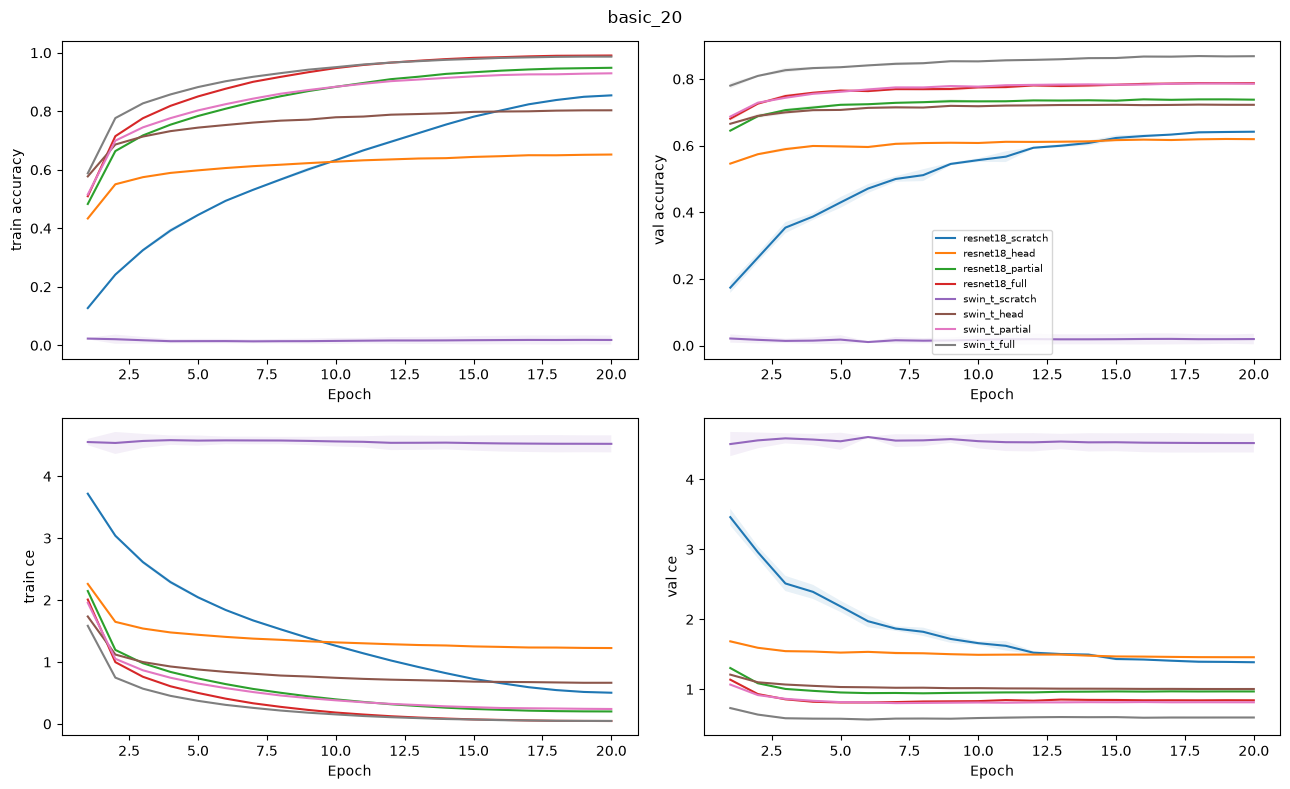

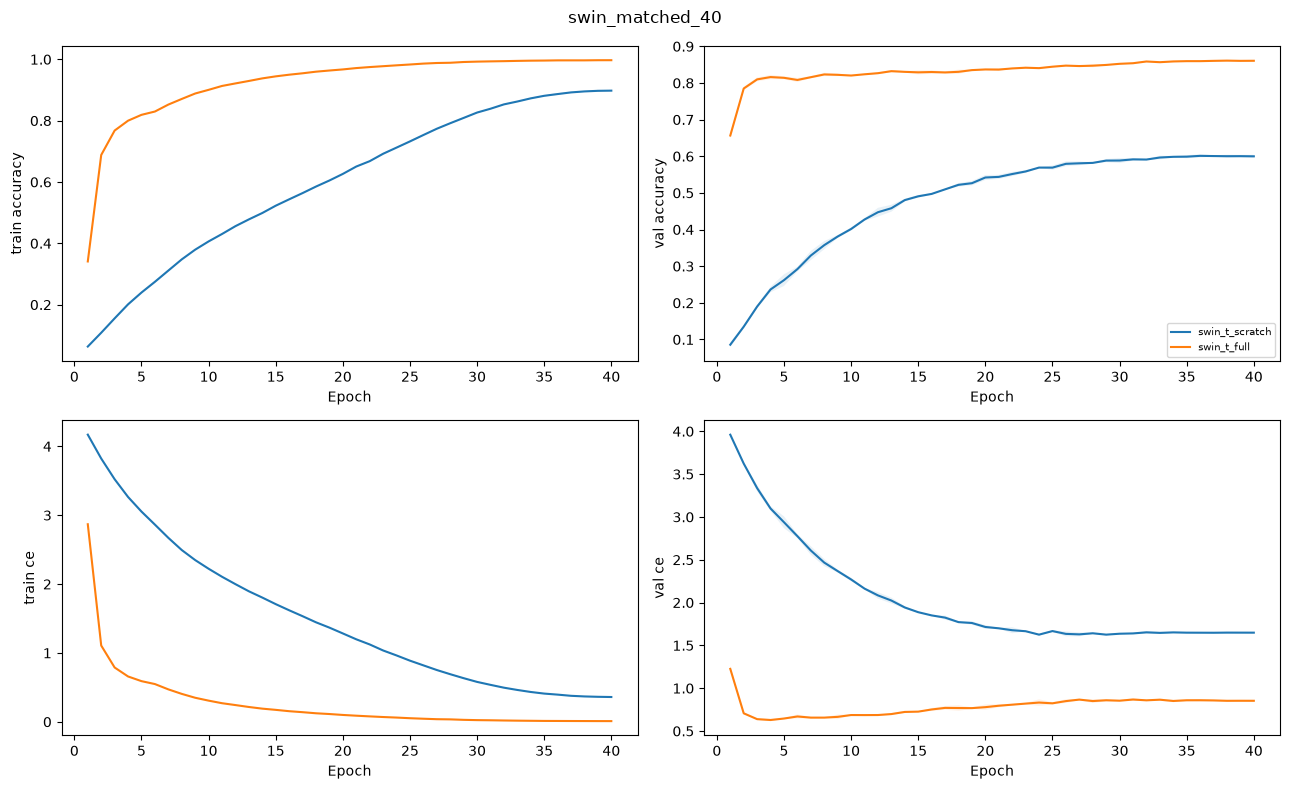

In [13]:
for study in studies:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for experiment in study["experiments"]:
        selected = histories[(histories["study"] == study["study"]) &
                             (histories["id"] == experiment["id"])]
        for ax, metric in zip(axes.flat, ["train_accuracy", "val_accuracy", "train_ce", "val_ce"]):
            curve = selected.groupby("epoch")[metric].agg(["mean", "std"])
            ax.plot(curve.index, curve["mean"], label=experiment["id"])
            ax.fill_between(curve.index, curve["mean"] - curve["std"],
                            curve["mean"] + curve["std"], alpha=0.1)
            ax.set(xlabel="Epoch", ylabel=metric.replace("_", " "))
    axes[0, 1].legend(fontsize=7)
    fig.suptitle(study["study"])
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{study["study"]}_curves.png', dpi=150)
    plt.show()
    plt.close(fig)


## 9. Confusion matrices and class errors

Confusion matrices sum the three seeds and normalize each true-class row. The error tables identify the most frequent class confusions and the classes with lowest recall.

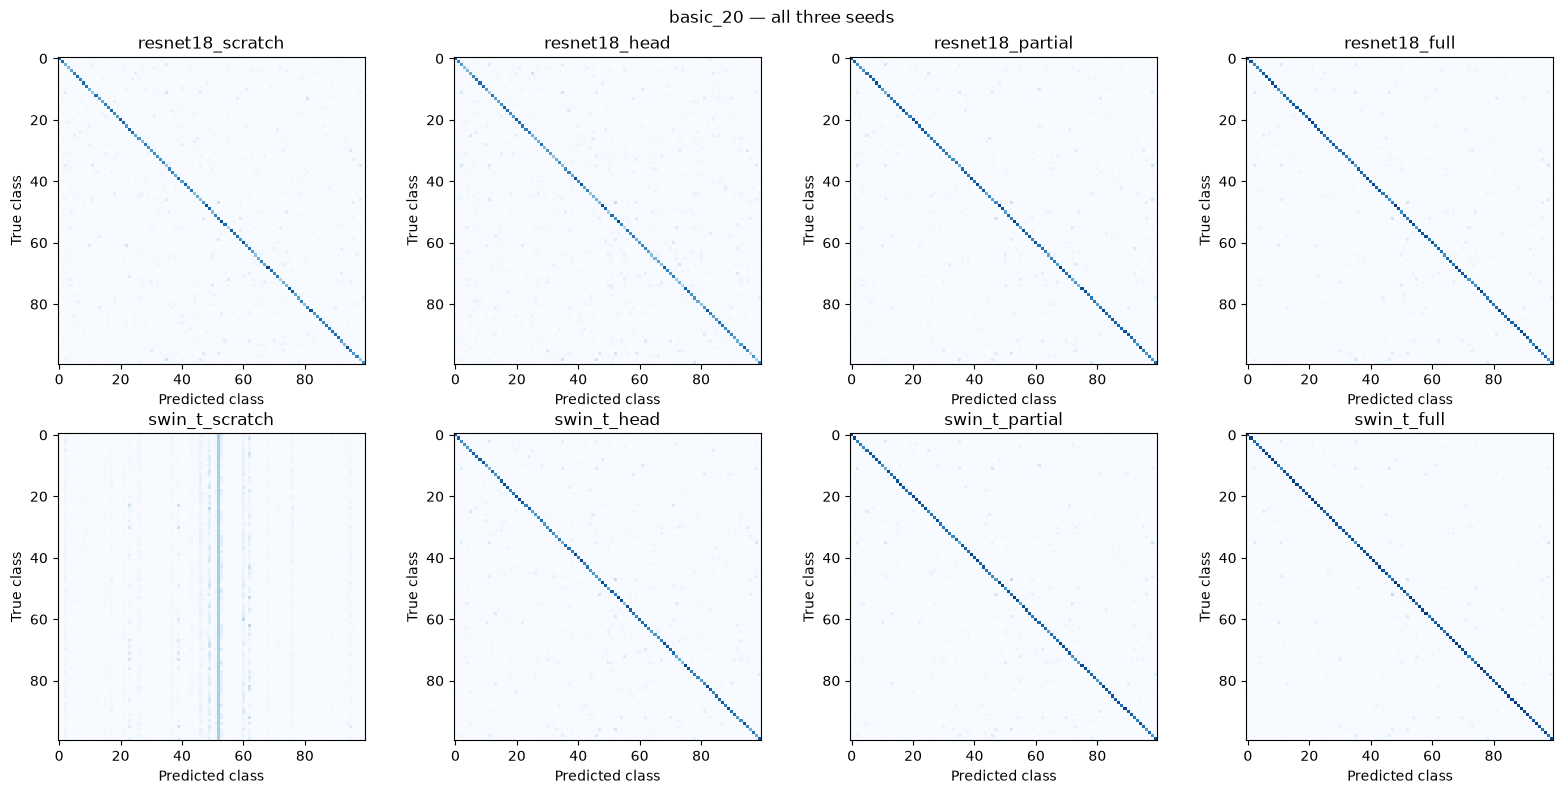

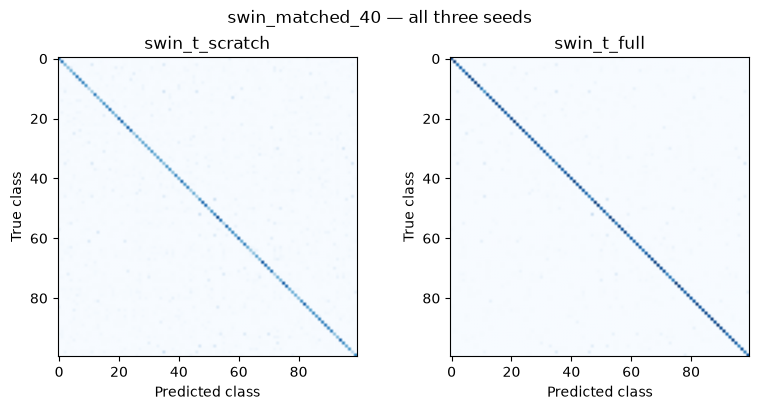

,study,id,true_class,predicted_class,count
0,basic_20,resnet18_scratch,maple_tree,oak_tree,61
1,basic_20,resnet18_scratch,woman,girl,58
2,basic_20,resnet18_scratch,plate,clock,47
3,basic_20,resnet18_scratch,bus,streetcar,47
4,basic_20,resnet18_scratch,boy,girl,47
5,basic_20,resnet18_head,maple_tree,oak_tree,69
6,basic_20,resnet18_head,bed,couch,57
7,basic_20,resnet18_head,woman,girl,52
8,basic_20,resnet18_head,willow_tree,oak_tree,52
9,basic_20,resnet18_head,boy,girl,51


,study,id,class,errors,recall
404,basic_20,swin_t_scratch,beaver,300,0.000000
401,basic_20,swin_t_scratch,aquarium_fish,300,0.000000
403,basic_20,swin_t_scratch,bear,300,0.000000
411,basic_20,swin_t_scratch,boy,300,0.000000
410,basic_20,swin_t_scratch,bowl,300,0.000000
196,basic_20,resnet18_head,willow_tree,219,0.270000
155,basic_20,resnet18_head,otter,218,0.273333
898,swin_matched_40,swin_t_scratch,woman,212,0.293333
174,basic_20,resnet18_head,shrew,211,0.296667
810,swin_matched_40,swin_t_scratch,bowl,206,0.313333


Results, histories, predictions, settings, checkpoints and figures saved to: /workspace/coursework/runs/A1/20261107T150346212192Z


In [14]:
confusion_export, confused_pairs, class_errors = {}, [], []
for study in studies:
    n_columns = min(4, len(study["experiments"]))
    n_rows = (len(study["experiments"]) + n_columns - 1) // n_columns
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(4 * n_columns, 4 * n_rows), squeeze=False)
    for ax, experiment in zip(axes.flat, study["experiments"]):
        matrix = matrices[study["study"], experiment["id"]]
        confusion_export[f'{study["study"]}/{experiment["id"]}'] = matrix.tolist()
        proportions = matrix / matrix.sum(1, keepdims=True)
        ax.imshow(proportions, cmap="Blues", vmin=0, vmax=1)
        ax.set(title=experiment["id"], xlabel="Predicted class", ylabel="True class")
        off_diagonal = matrix.copy()
        np.fill_diagonal(off_diagonal, 0)
        for flat_index in np.argsort(off_diagonal.ravel())[-5:][::-1]:
            actual, predicted = np.unravel_index(flat_index, matrix.shape)
            if off_diagonal[actual, predicted] > 0:
                confused_pairs.append({
                    "study": study["study"], "id": experiment["id"],
                    "true_class": classes[actual], "predicted_class": classes[predicted],
                    "count": int(off_diagonal[actual, predicted]),
                })
        for class_id in range(N_CLASSES):
            class_errors.append({
                "study": study["study"], "id": experiment["id"], "class": classes[class_id],
                "errors": int(matrix[class_id].sum() - matrix[class_id, class_id]),
                "recall": float(proportions[class_id, class_id]),
            })
    for ax in axes.flat[len(study["experiments"]):]:
        ax.axis("off")
    fig.suptitle(study["study"] + " — all three seeds")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{study["study"]}_confusion.png', dpi=150)
    plt.show()
    plt.close(fig)

(RUN_DIR / "confusion.json").write_text(json.dumps({"classes": classes, "matrices": confusion_export}))
confused_pairs = pd.DataFrame(confused_pairs)
class_errors = pd.DataFrame(class_errors)
confused_pairs.to_csv(RUN_DIR / "confused_pairs.csv", index=False)
class_errors.to_csv(RUN_DIR / "class_errors.csv", index=False)
display(confused_pairs)
display(class_errors.sort_values("recall").groupby(["study", "id"], sort=False).head(5))
print("Results, histories, predictions, settings, checkpoints and figures saved to:", RUN_DIR.resolve())


## Findings

Full fine-tuning gives the highest accuracy within both architectures in the 20-epoch study: Swin-T reaches 86.54% and ResNet18 78.93%. Swin-T scratch reaches only 2.19% under that schedule, so the large gap also reflects poor optimization of the scratch configuration.

Under the matched 40-epoch schedule, scratch Swin-T reaches 60.00% and pretrained Swin-T 86.45%. Their paired difference is 26.45 ± 0.40 percentage points across three seeds. The longer study also changes learning rate, weight decay and warmup relative to the 20-epoch study; its improvement cannot be assigned to epoch count alone.